Set 4 - Optimization
Ali khabazian - 402416066

In [ ]:
Q1 - central difference

In [1]:
def compute_derivative(data, h, neighbors):
    derivative = []
    for i in range(neighbors // 2, len(data) - neighbors // 2):
        if neighbors == 3:
            derivative_val = (data[i + 1] - data[i - 1]) / (2 * h)
        elif neighbors == 5:
            derivative_val = (-data[i + 2] + 8 * data[i + 1] - 8 * data[i - 1] + data[i - 2]) / (12 * h)
        elif neighbors == 7:
            derivative_val = (data[i - 3] - 9 * data[i - 2] + 45 * data[i - 1] - 45 * data[i + 1] + 9 * data[i + 2] - data[i + 3]) / (60 * h)
        elif neighbors == 9:
            derivative_val = (-3 * data[i - 4] + 32 * data[i - 3] - 168 * data[i - 2] + 672 * data[i - 1] - 672 * data[i + 1] + 168 * data[i + 2] - 32 * data[i + 3] + 3 * data[i + 4]) / (840 * h)
        else:
            raise ValueError("Invalid number of neighbors. Supported values are 3, 5, 7, and 9.")
        derivative.append(derivative_val)
    return derivative

In [2]:
data=[]
with open("C:\\Users\\user\\OneDrive\\Desktop\\software\\dataprofile.txt", "r") as file:
    lines = file.readlines()
    for line in lines:
        parts = line.split("\t")
        if len(parts) == 2:
            data.append(float(parts[1]))

In [3]:
h = 1 
neighbors = [3, 5, 7, 9]
for n in neighbors:
    derivative = compute_derivative(data, h, n)
    print(f"Derivative with {n}-point neighbors: {derivative}")

Derivative with 3-point neighbors: [0.080671805, -0.04305742900000009, 0.6215432320000001, 0.21558574750000004, 0.06585292600000003, -0.187398725, -0.166779436, 0.5873072945, 0.709178844, -0.6861398615, -0.36510238000000006, 0.27764934499999994, 0.4804361885, 0.39429025799999995, -0.18065553450000005, -0.03802448099999989, -0.3744476175, -0.15391480200000007, -0.2824844205, -0.15388249349999994, 0.369926321, -0.6433713435, 0.15312823800000008, 0.016273300499999976, -0.988796361, -0.3768841315, 0.003890854499999999, 0.348814071, 0.029712576999999997, 0.06688951800000001, -0.60056717, -0.5598215965, 0.3652812605, -0.27597643099999997, -0.6890378515, 0.1344606175, 0.12101658800000004, 0.155579886, -0.550728101, -0.48548981300000005, 0.602917256, 0.22329720000000008, 0.108755504, -0.5745781675000001, -0.193296268, 0.2246653260000001, -0.08062115550000004, -0.04603188749999998, -0.45232493149999997, -0.0379257850000001, 0.9500860044999999, -0.08877514649999996, -0.028004932499999968, 0.3816

Q2 - Implicit and Explicit
part A

In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
x0 = 1.0
f0 = 1.0
delta_x = 0.5
n_steps = 10

x_values = np.zeros(n_steps + 1)
f_explicit = np.zeros(n_steps + 1)
f_implicit = np.zeros(n_steps + 1)

x_values[0] = x0
f_explicit[0] = f0
f_implicit[0] = f0

In [17]:
#explicit;

for i in range(n_steps):
    x_values[i + 1] = x_values[i] + delta_x
    f_explicit[i + 1] = f_explicit[i] + f_explicit[i]**2 * delta_x

#implicit:
for i in range(n_steps):
    x_values[i + 1] = x_values[i] + delta_x
    f_implicit[i + 1] = f_implicit[i] / (1 - f_implicit[i] * delta_x)

# Analytical solution
analytical_sol = 1 / (1 - x_values + 1)

C:\Users\user\AppData\Local\Temp\ipykernel_17524\2614578813.py:10: RuntimeWarning: divide by zero encountered in double_scalars
  f_implicit[i + 1] = f_implicit[i] / (1 - f_implicit[i] * delta_x)
C:\Users\user\AppData\Local\Temp\ipykernel_17524\2614578813.py:10: RuntimeWarning: invalid value encountered in double_scalars
  f_implicit[i + 1] = f_implicit[i] / (1 - f_implicit[i] * delta_x)
C:\Users\user\AppData\Local\Temp\ipykernel_17524\2614578813.py:13: RuntimeWarning: divide by zero encountered in divide
  analytical_sol = 1 / (1 - x_values + 1)


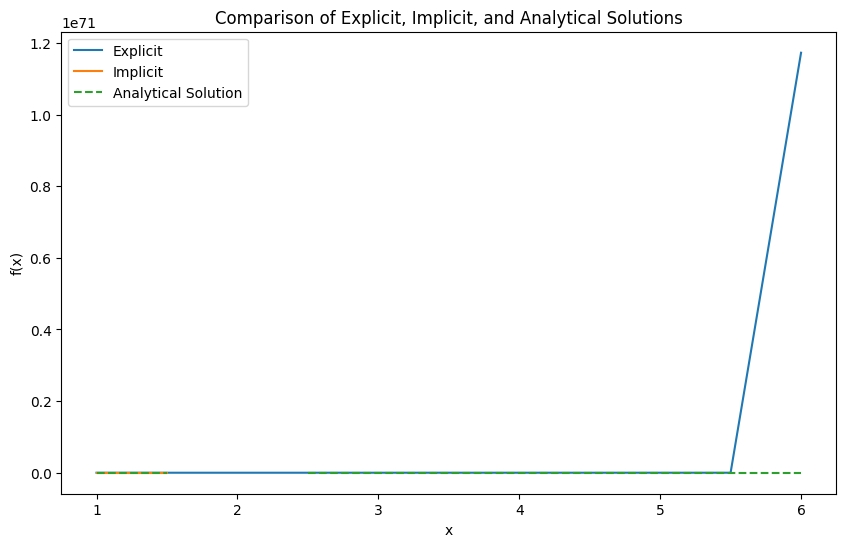

In [18]:
plt.figure(figsize=(10, 6))
plt.plot(x_values, f_explicit, label='Explicit')
plt.plot(x_values, f_implicit, label='Implicit')
plt.plot(x_values, analytical_sol, '--', label='Analytical Solution')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Comparison of Explicit, Implicit, and Analytical Solutions')
plt.legend()
plt.show()

Q2 - Implicit and Explicit
part B

In [14]:
import numpy as np
import matplotlib.pyplot as plt


In [21]:
x0 = 1.0
f0 = 1.0
delta_x = 0.5
n_steps = 10

x_values = np.zeros(n_steps + 1)
f_explicit = np.zeros(n_steps + 1)
f_implicit = np.zeros(n_steps + 1)

x_values[0] = x0
f_explicit[0] = f0
f_implicit[0] = f0

In [22]:
#Explicit:
for i in range(n_steps):
    x_values[i + 1] = x_values[i] + delta_x
    f_explicit[i + 1] = f_explicit[i] - f_explicit[i] * delta_x

# Implicit:
for i in range(n_steps):
    x_values[i + 1] = x_values[i] + delta_x
    f_implicit[i + 1] = f_implicit[i] / (1 + delta_x)

# Analytical solution:
analytical_sol = np.exp(-x_values + 1)

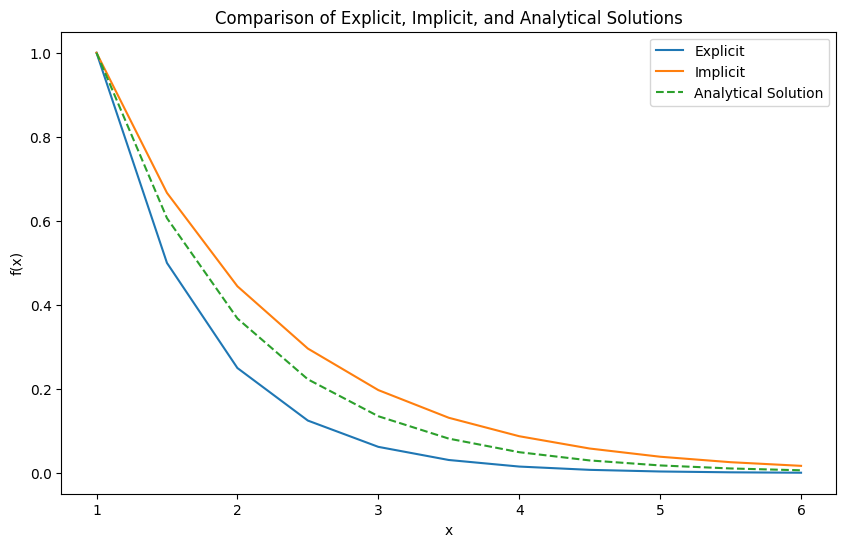

In [23]:
plt.figure(figsize=(10, 6))
plt.plot(x_values, f_explicit, label='Explicit')
plt.plot(x_values, f_implicit, label='Implicit')
plt.plot(x_values, analytical_sol, '--', label='Analytical Solution')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Comparison of Explicit, Implicit, and Analytical Solutions')
plt.legend()
plt.show()

Q4 - comparison of Euler and RF4

In [24]:
def euler_method(f, y0, t):
    """
    Solve the system of ODEs using Euler's method.
    """
    n = len(t)
    y = np.zeros((n, len(y0)))
    y[0] = y0
    
    for i in range(1, n):
        dt = t[i] - t[i-1]
        y[i] = y[i-1] + f(t[i-1], y[i-1]) * dt
    
    return y

In [25]:
def rk4_method(f, y0, t):
    """
    Solve the system of ODEs using the Runge-Kutta-Fehlberg (RK4) method.
    """
    n = len(t)
    y = np.zeros((n, len(y0)))
    y[0] = y0
    
    for i in range(1, n):
        dt = t[i] - t[i-1]
        k1 = f(t[i-1], y[i-1])
        k2 = f(t[i-1] + 0.5*dt, y[i-1] + 0.5*dt*k1)
        k3 = f(t[i-1] + 0.5*dt, y[i-1] + 0.5*dt*k2)
        k4 = f(t[i-1] + dt, y[i-1] + dt*k3)
        y[i] = y[i-1] + (dt/6) * (k1 + 2*k2 + 2*k3 + k4)
    
    return y

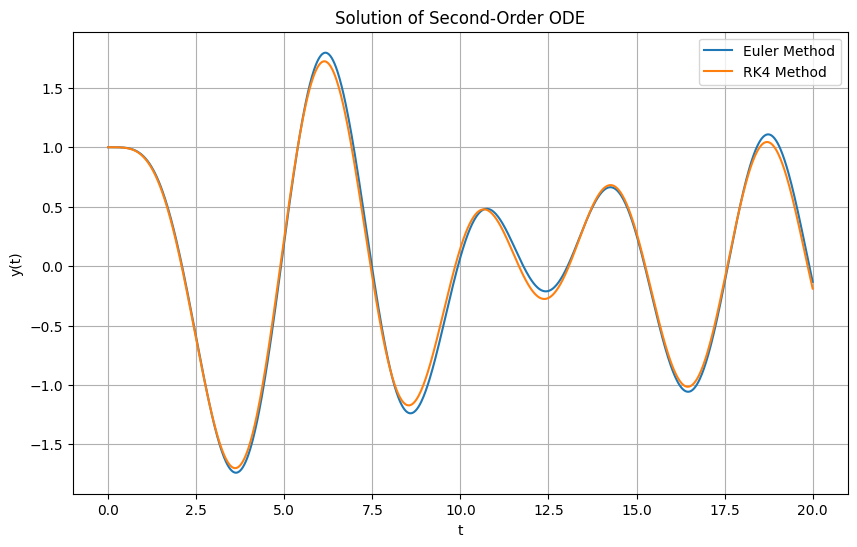

In [28]:
def f(t, y):
    """
    Define the system of ODEs.
    """
    y1, y2 = y
    a = 0.2  
    w = 1.0  
    w1 = 1.5  
    dy1_dt = y2
    dy2_dt = -a * y2 - w**2 * y1 + np.cos(w1 * t)
    return np.array([dy1_dt, dy2_dt])

def main():
    
    y0 = np.array([1.0, 0.0])  # y(0) = A, dy(0)/dt = 0
    t_start = 0
    t_end = 20
    num_points = 1000
    t = np.linspace(t_start, t_end, num_points)
    
    # Solve using Euler's method
    y_euler = euler_method(f, y0, t)
    
    # Solve using RK4 method
    y_rk4 = rk4_method(f, y0, t)

    plt.figure(figsize=(10, 6))
    plt.plot(t, y_euler[:, 0], label='Euler Method')
    plt.plot(t, y_rk4[:, 0], label='RK4 Method')
    plt.xlabel('t')
    plt.ylabel('y(t)')
    plt.title('Solution of Second-Order ODE')
    plt.legend()
    plt.grid(True)
    plt.show()

if __name__ == "__main__":
    main()

Q4 - iterative relaxation

In [33]:
def iterative_relaxation(f, y0, t, max_iter=1000, tolerance=1e-6):
    """
    Solve the system of ODEs using the iterative relaxation method.
    """
    n = len(t)
    y = np.zeros((n, len(y0)))
    y[0] = y0
    
    for i in range(1, n):
        dt = t[i] - t[i-1]
        y[i] = y[i-1]  
        
        for _ in range(max_iter):
            y_old = np.copy(y[i])
            y[i] = y[i-1] + f(t[i-1], y[i]) * dt
            if np.max(np.abs(y[i] - y_old)) < tolerance:
                break
    
    return y


In [34]:
def f(t, y):
    """
    Define the system of ODEs.
    """
    y1, y2 = y
    a = 0.2  
    w = 1.0  
    w1 = 1.5  
    dy1_dt = y2
    dy2_dt = -a * y2 - w**2 * y1 + np.cos(w1 * t)
    return np.array([dy1_dt, dy2_dt])

def main():
    
    y0 = np.array([1.0, 0.0])  # y(0) = A, dy(0)/dt = 0
    t_start = 0
    t_end = 20
    num_points = 1000
    t = np.linspace(t_start, t_end, num_points)
    
    
    y_iterative_relaxation = iterative_relaxation(f, y0, t)
    
    
    plt.figure(figsize=(10, 6))
    plt.plot(t, y_iterative_relaxation[:, 0], label='Iterative Relaxation Method')
    plt.xlabel('t')
    plt.ylabel('y(t)')
    plt.title('Solution of Second-Order ODE using Iterative Relaxation Method')
    plt.legend()
    plt.grid(True)
    plt.show()

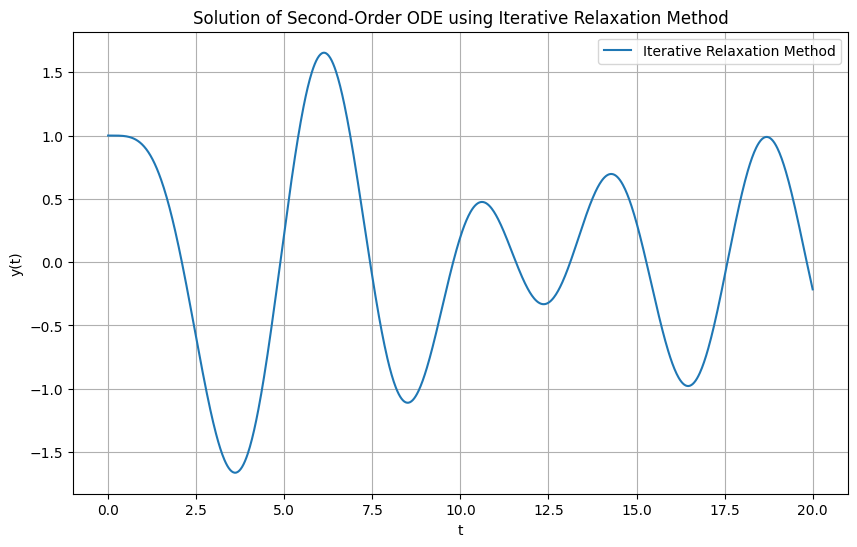

In [35]:
if __name__ == "__main__":
    main()

Q5 - finite difference

In [36]:
def finite_difference_method(f, y0, t, N):
    """
    Solve the system of ODEs using the finite difference method.
    """
    dt = (t[-1] - t[0]) / (N - 1)
    y = np.zeros((N, len(y0)))
    y[0] = y0
    
    for i in range(1, N):
        t_i = t[i]
        y[i] = y[i-1]  
        
        dy1_dt = (y[i-1, 1] - y[i-1, 0]) / dt
        dy2_dt = -0.2 * y[i-1, 1] - y[i-1, 0] + np.cos(1.5 * t_i)
        
        y[i, 0] = y[i-1, 0] + dy1_dt * dt
        y[i, 1] = y[i-1, 1] + dy2_dt * dt
    
    return y

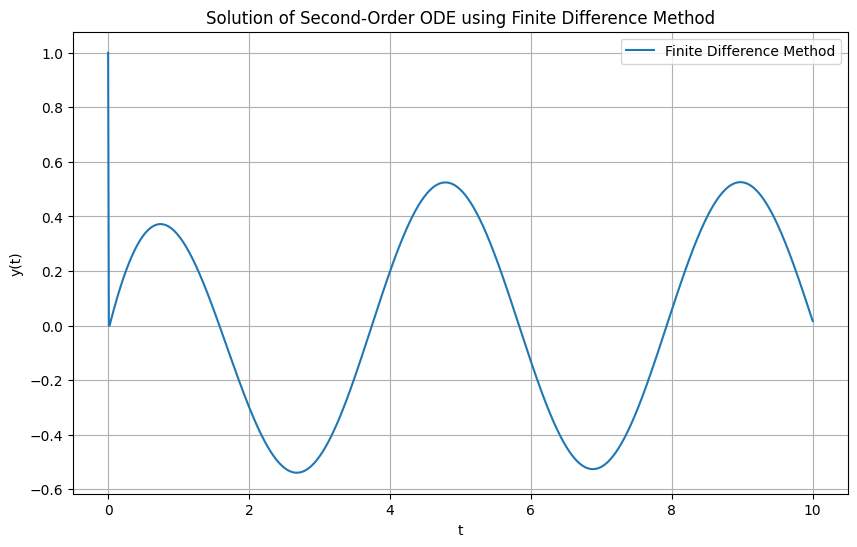

In [37]:
def f(t, y):
    """
    Define the system of ODEs.
    """
    return np.array([y[1], -0.2 * y[1] - y[0] + np.cos(1.5 * t)])

def main():
    
    y0 = np.array([1.0, 0.0])  # y(0) = A, dy(0)/dt = 0
    t_start = 0
    t_end = 10
    N = 1000
    t = np.linspace(t_start, t_end, N)
    
    y_finite_difference = finite_difference_method(f, y0, t, N)
    
    plt.figure(figsize=(10, 6))
    plt.plot(t, y_finite_difference[:, 0], label='Finite Difference Method')
    plt.xlabel('t')
    plt.ylabel('y(t)')
    plt.title('Solution of Second-Order ODE using Finite Difference Method')
    plt.legend()
    plt.grid(True)
    plt.show()

if __name__ == "__main__":
    main()

Q6 - relaxation method

In [38]:
def laplace_relaxation_method(psi, L, max_iter=1000, tol=1e-6):
    """
    Solve Laplace's equation using the relaxation method.
    """
    nx, ny = psi.shape
    psi_new = np.copy(psi)
    dx = L / (nx - 1)
    dy = L / (ny - 1)
    
    for _ in range(max_iter):
        psi_old = np.copy(psi_new)
        
        # Update interior points
        for i in range(1, nx - 1):
            for j in range(1, ny - 1):
                psi_new[i, j] = 0.25 * (psi_old[i+1, j] + psi_old[i-1, j] + psi_old[i, j+1] + psi_old[i, j-1])
        
        # Check convergence
        if np.max(np.abs(psi_new - psi_old)) < tol:
            break
    
    return psi_new

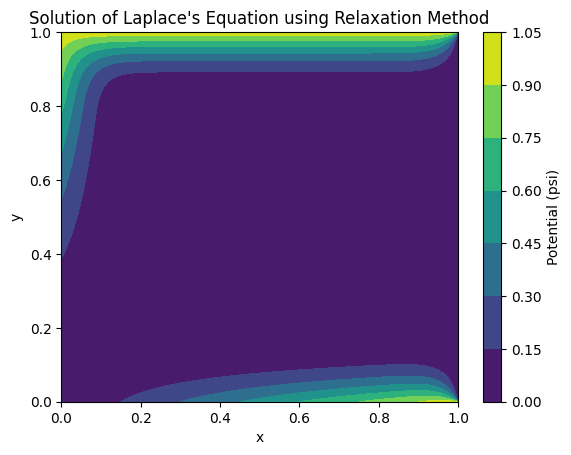

In [39]:
def main():
    
    L = 1.0  
    nx = 300  
    ny = 300  
    
    psi = np.zeros((nx, ny))
    
    psi[0, :] = np.linspace(0, L, ny)**2  # psi(0, y) = y^2
    psi[:, 0] = np.linspace(0, L, nx)     # psi(x, 0) = x
    psi[-1, :] = 0                         # psi(L, y) = 0
    psi[:, -1] = 1                         # psi(x, L) = 1
    
    psi = laplace_relaxation_method(psi, L)
    
    X, Y = np.meshgrid(np.linspace(0, L, nx), np.linspace(0, L, ny))
    plt.contourf(X, Y, psi.T, cmap='viridis')
    plt.colorbar(label='Potential (psi)')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Solution of Laplace\'s Equation using Relaxation Method')
    plt.show()

if __name__ == "__main__":
    main()